<a href="https://colab.research.google.com/github/m1Febriansyah/244107020199-ML-12/blob/main/JS07Praktikum1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# import package
import numpy as np
import pandas as pd

In [ ]:
# baca data dari file CSV
data = pd.read_csv('dataset.csv')

In [ ]:
# melihat beberapa data awal
data.head()

# mengecek ukuran data
data.shape

# informasi tentang data
data.info()

# deskripsi data
data.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Email                 500 non-null    object 
 1   Address               500 non-null    object 
 2   Avatar                500 non-null    object 
 3   Avg. Session Length   500 non-null    float64
 4   Time on App           500 non-null    float64
 5   Time on Website       500 non-null    float64
 6   Length of Membership  500 non-null    float64
 7   Yearly Amount Spent   500 non-null    float64
dtypes: float64(5), object(3)
memory usage: 31.4+ KB


,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
count,500.000000,500.000000,500.000000,500.000000,500.000000
mean,33.053194,12.052488,37.060445,3.533462,499.314038
std,0.992563,0.994216,1.010489,0.999278,79.314782
min,29.532429,8.508152,33.913847,0.269901,256.670582
25%,32.341822,11.388153,36.349257,2.930450,445.038277
50%,33.082008,11.983231,37.069367,3.533975,498.887875
75%,33.711985,12.753850,37.716432,4.126502,549.313828
max,36.139662,15.126994,40.005182,6.922689,765.518462


In [ ]:
# import library untuk visualisasi
import matplotlib.pyplot as plt
import seaborn as sns

/usr/local/lib/python3.13/dist-packages/seaborn/axisgrid.py:2100: UserWarning: The `size` parameter has been renamed to `height`; please update your code.
  warnings.warn(msg, UserWarning)


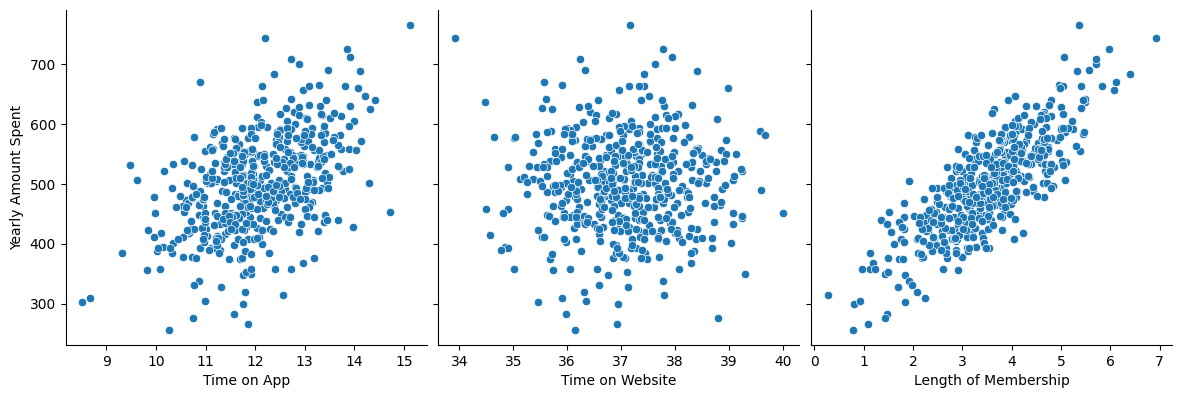

In [ ]:
# visualisasi data dengan pairplot
sns.pairplot(data, x_vars=['Time on App', 'Time on Website', 'Length of Membership'],
             y_vars='Yearly Amount Spent', size=4, aspect=1, kind='scatter')
plt.show()

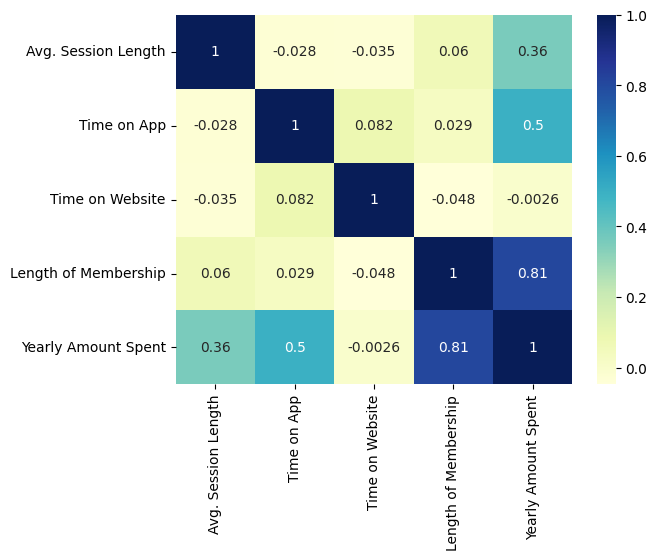

In [ ]:
# visualisasi korelasi dengan heatmap
sns.heatmap(data.corr(numeric_only=True), cmap="YlGnBu", annot=True)
plt.show()

In [ ]:
# Membuat variabel bebas X dan Y, contoh pengambilan dari analisis korelasi sebelumnya
X = data['Length of Membership']
y = data['Yearly Amount Spent']

In [ ]:
# Pembagian data latih dan data uji dengan proporsi 7:3
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.7, test_size=0.3, random_state=100)

In [ ]:
# Training model
import statsmodels.api as sm

X_train_sm = sm.add_constant(X_train)
lr = sm.OLS(y_train, X_train_sm).fit()

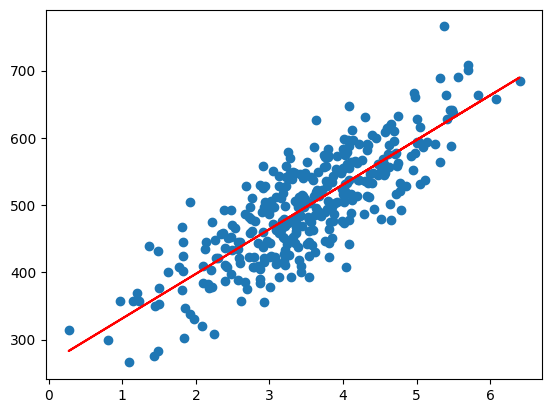

In [ ]:
# Visualisasi garis regresi
plt.scatter(X_train, y_train)
plt.plot(X_train, 265.2483 + 66.3015*X_train, 'r')
plt.show()

In [ ]:
# Prediksi pada data uji
X_test_sm = sm.add_constant(X_test)
y_test_pred = lr.predict(X_test_sm)

In [ ]:
# Hitung nilai R-squared
from sklearn.metrics import r2_score

r_squared = r2_score(y_test, y_test_pred)

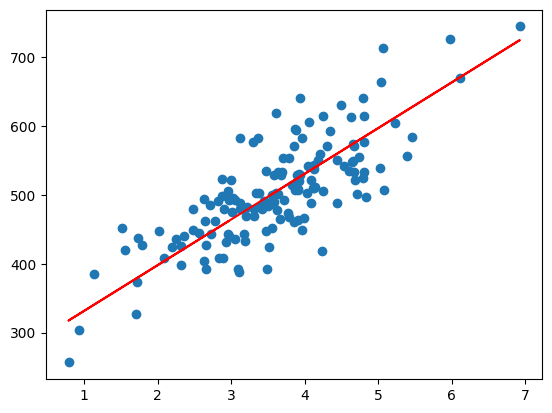

In [ ]:
# Visualisasi data uji dan hasil prediksi
plt.scatter(X_test, y_test)
plt.plot(X_test, y_test_pred, 'r')
plt.show()

In [1]:
# import package
import numpy as np
import pandas as pd

# baca data dari file CSV
data = pd.read_csv('properti_multi_kota.csv')

# Imputasi missing value & filter outlier ekstrem agar regresi linier dan grafik terbaca jelas
for col in ['luas_bangunan', 'jumlah_kamar', 'jumlah_kamar_mandi']:
    data[col] = data[col].fillna(data[col].median())

data = data[
    (data['luas_m2'] > 0) & (data['luas_m2'] <= data['luas_m2'].quantile(0.95)) &
    (data['luas_bangunan'] > 0) & (data['luas_bangunan'] <= data['luas_bangunan'].quantile(0.95)) &
    (data['harga'] > 1e7) & (data['harga'] <= data['harga'].quantile(0.95))
].copy()

In [2]:
# melihat beberapa data awal
data.head()
# mengecek ukuran data
data.shape
# informasi tentang data
data.info()
# deskripsi data
data.describe()

<class 'pandas.core.frame.DataFrame'>
Index: 58881 entries, 0 to 64648
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   sumber              58881 non-null  object 
 1   lokasi              58881 non-null  object 
 2   luas_m2             58881 non-null  float64
 3   luas_bangunan       58881 non-null  float64
 4   jumlah_kamar        58881 non-null  float64
 5   jumlah_kamar_mandi  58881 non-null  float64
 6   usia_bangunan       4105 non-null   float64
 7   harga               58881 non-null  float64
dtypes: float64(6), object(2)
memory usage: 4.0+ MB


,luas_m2,luas_bangunan,jumlah_kamar,jumlah_kamar_mandi,usia_bangunan,harga
count,58881.000000,58881.000000,5.888100e+04,5.888100e+04,4105.000000,5.888100e+04
mean,116.559911,83.937169,6.880829e+03,1.586427e+04,1208.972473,1.038618e+09
std,77.022203,67.032993,1.669043e+06,3.849101e+06,977.153274,1.002566e+09
min,1.000000,1.000000,0.000000e+00,0.000000e+00,0.000000,1.155000e+07
25%,72.000000,39.000000,2.000000e+00,1.000000e+00,24.000000,3.600000e+08
50%,93.000000,60.000000,2.000000e+00,1.000000e+00,2010.000000,6.698000e+08
75%,129.000000,100.000000,3.000000e+00,2.000000e+00,2021.000000,1.360650e+09
max,600.000000,400.000000,4.050000e+08,9.340000e+08,2026.000000,5.700000e+09


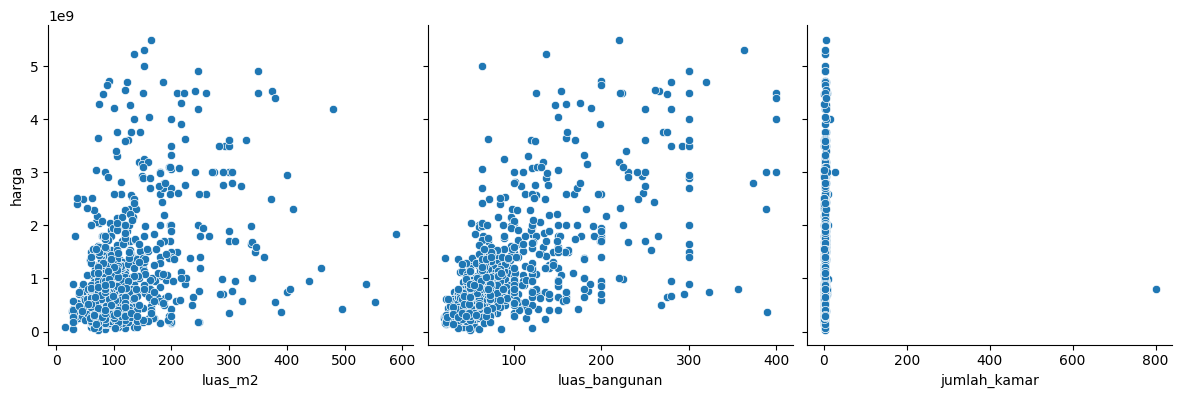

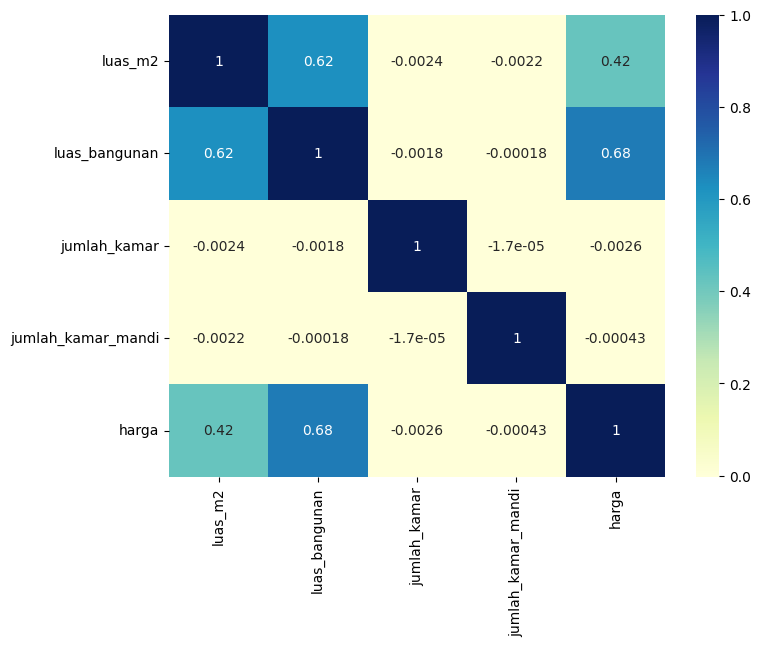

In [3]:
# import library untuk visualisasi
import matplotlib.pyplot as plt
import seaborn as sns

# visualisasi data dengan pairplot (menggunakan sampel 1000 data agar rendering cepat)
sns.pairplot(
    data.sample(n=min(1000, len(data)), random_state=42),
    x_vars=['luas_m2', 'luas_bangunan', 'jumlah_kamar'],
    y_vars='harga', height=4, aspect=1, kind='scatter'
)
plt.show()

# visualisasi korelasi dengan heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(data[['luas_m2', 'luas_bangunan', 'jumlah_kamar', 'jumlah_kamar_mandi', 'harga']].corr(), cmap="YlGnBu", annot=True)
plt.show()

                            OLS Regression Results                            
Dep. Variable:                  harga   R-squared:                       0.455
Model:                            OLS   Adj. R-squared:                  0.455
Method:                 Least Squares   F-statistic:                 3.445e+04
Date:                Tue, 17 Nov 2026   Prob (F-statistic):               0.00
Time:                        22:20:37   Log-Likelihood:            -9.0021e+05
No. Observations:               41216   AIC:                         1.800e+06
Df Residuals:                   41214   BIC:                         1.800e+06
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const          1.901e+08   5.86e+06     32.463

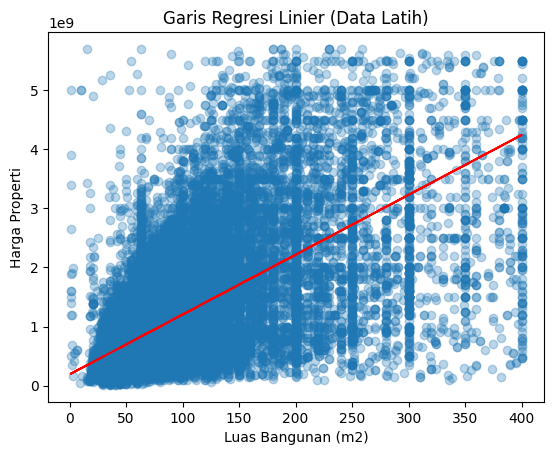

In [4]:
# Membuat variabel bebas X dan target y
X = data['luas_bangunan']
y = data['harga']

# Pembagian data latih dan data uji dengan proporsi 7:3
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.7, test_size=0.3, random_state=100)

# Training model menggunakan StatsModels
import statsmodels.api as sm

X_train_sm = sm.add_constant(X_train)
lr = sm.OLS(y_train, X_train_sm).fit()
print(lr.summary())

# Visualisasi garis regresi pada data latih
plt.scatter(X_train, y_train, alpha=0.3)
plt.plot(X_train, lr.params['const'] + lr.params['luas_bangunan'] * X_train, 'r')
plt.xlabel('Luas Bangunan (m2)')
plt.ylabel('Harga Properti')
plt.title('Garis Regresi Linier (Data Latih)')
plt.show()

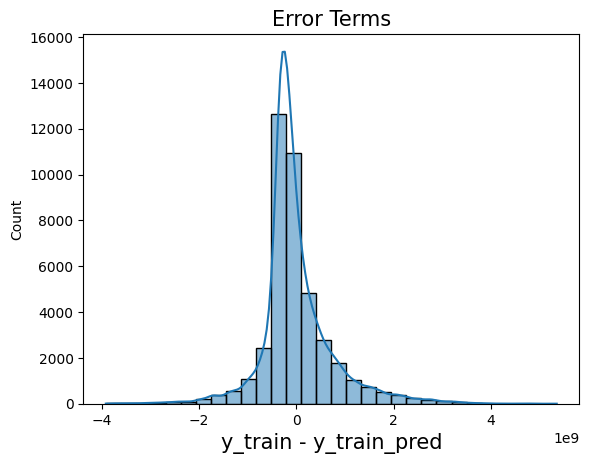

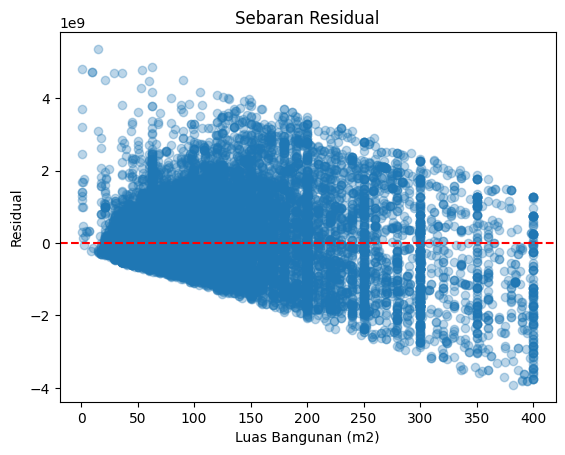

In [5]:
# Prediksi nilai y dari data latih dan hitung residual
y_train_pred = lr.predict(X_train_sm)
res = (y_train - y_train_pred)

# Histogram residual (menggunakan histplot sebagai pengganti distplot yang sudah deprecated)
fig = plt.figure()
sns.histplot(res, bins=30, kde=True)
plt.title('Error Terms', fontsize=15)
plt.xlabel('y_train - y_train_pred', fontsize=15)
plt.show()

# Scatter plot residual
plt.scatter(X_train, res, alpha=0.3)
plt.axhline(y=0, color='r', linestyle='--')
plt.xlabel('Luas Bangunan (m2)')
plt.ylabel('Residual')
plt.title('Sebaran Residual')
plt.show()

Nilai R-squared pada data uji: 0.4646


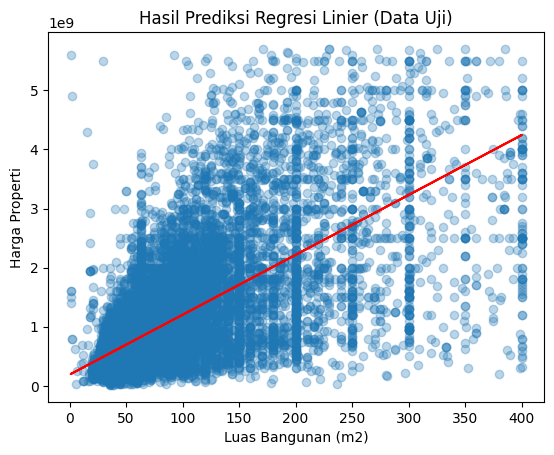

In [6]:
# Prediksi pada data uji
X_test_sm = sm.add_constant(X_test)
y_test_pred = lr.predict(X_test_sm)

# Hitung nilai R-squared
from sklearn.metrics import r2_score

r_squared = r2_score(y_test, y_test_pred)
print(f"Nilai R-squared pada data uji: {r_squared:.4f}")

# Visualisasi data uji dan hasil prediksi
plt.scatter(X_test, y_test, alpha=0.3)
plt.plot(X_test, y_test_pred, 'r')
plt.xlabel('Luas Bangunan (m2)')
plt.ylabel('Harga Properti')
plt.title('Hasil Prediksi Regresi Linier (Data Uji)')
plt.show()